<a href="https://colab.research.google.com/github/Renessa14/House_Price_Prediction-2024331/blob/main/House_Price_Predictionipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Problem Statement** A real-estate platform wants to give sellers an instant, data-driven price estimate for a house based on area-level economic and housing indicators. You will build a regression model that predicts house price from those indicators.

**Business Objective** Predict house prices accurately so that a platform can display fair, consistent price estimates instead of relying only on manual valuation by agents.


**Why This Project Matters** Price prediction is one of the most common real-world regression problems and appears constantly in real-estate, insurance, and resale-value applications. It is an excellent project to practice handling multiple continuous features and explaining a regression model to business stakeholders.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error


df = pd.read_csv('/content/USA_Housing.csv')


print(df.head())
print(df.info())

   Avg. Area Income  Avg. Area House Age  Avg. Area Number of Rooms  \
0      79545.458574             5.682861                   7.009188   
1      79248.642455             6.002900                   6.730821   
2      61287.067179             5.865890                   8.512727   
3      63345.240046             7.188236                   5.586729   
4      59982.197226             5.040555                   7.839388   

   Avg. Area Number of Bedrooms  Area Population         Price  \
0                          4.09     23086.800503  1.059034e+06   
1                          3.09     40173.072174  1.505891e+06   
2                          5.13     36882.159400  1.058988e+06   
3                          3.26     34310.242831  1.260617e+06   
4                          4.23     26354.109472  6.309435e+05   

                                             Address  
0  208 Michael Ferry Apt. 674\nLaurabury, NE 3701...  
1  188 Johnson Views Suite 079\nLake Kathleen, CA...  
2  9127 Eli

In [ ]:
# Check for missing values
print(df.isnull().sum())

# Rename columns for easier coding
df = df.rename(columns={
    'Avg. Area Income': 'avg_area_income',
    'Avg. Area House Age': 'avg_area_house_age',
    'Avg. Area Number of Rooms': 'avg_area_rooms',
    'Avg. Area Number of Bedrooms': 'avg_area_bedrooms',
    'Area Population': 'area_population',
    'Price': 'price',
    'Address': 'address'
})


df = df.drop(columns=['address'])


print((df['price'] < 0).sum())
print((df['area_population'] < 0).sum())

Avg. Area Income                0
Avg. Area House Age             0
Avg. Area Number of Rooms       0
Avg. Area Number of Bedrooms    0
Area Population                 0
Price                           0
Address                         0
dtype: int64
0
0


In [ ]:
# Check for missing values
print("Missing values:\n", df.isnull().sum())

# Renaming columns
df = df.rename(columns={
    'Avg. Area Income': 'avg_area_income',
    'Avg. Area House Age': 'avg_area_house_age',
    'Avg. Area Number of Rooms': 'avg_area_rooms',
    'Avg. Area Number of Bedrooms': 'avg_area_bedrooms',
    'Area Population': 'area_population',
    'Price': 'price',
    'Address': 'address'
})


df = df.drop(columns=['address'], errors='ignore')


print("Negative prices:", (df['price'] < 0).sum() if 'price' in df.columns else "Column 'price' not found")
print("Negative populations:", (df['area_population'] < 0).sum() if 'area_population' in df.columns else "Column 'area_population' not found")

Missing values:
 avg_area_income       0
avg_area_house_age    0
avg_area_rooms        0
avg_area_bedrooms     0
area_population       0
price                 0
dtype: int64
Negative prices: 0
Negative populations: 0


## Exploratory Data Analysis (EDA)
We will now generate the 4 required EDA visualizations according to the project workflow guidelines to understand the feature distributions and correlations.

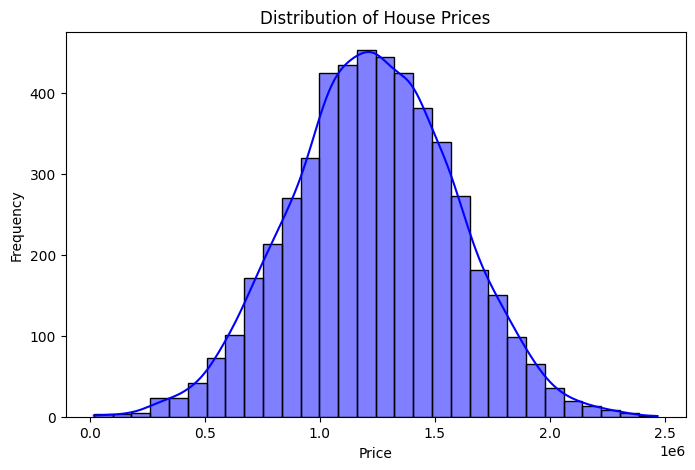

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(df['price'], kde=True, color='blue', bins=30)
plt.title('Distribution of House Prices')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.show()

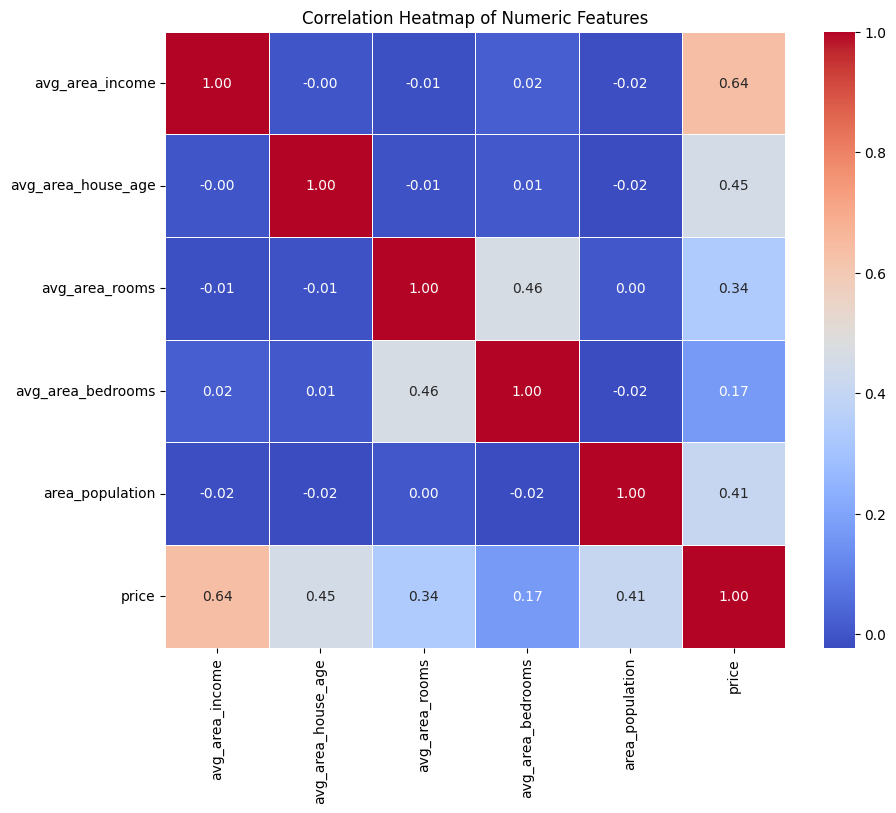

In [ ]:
plt.figure(figsize=(10, 8))
numeric_cols = df.select_dtypes(include=[np.number]).columns
correlation_matrix = df[numeric_cols].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap of Numeric Features')
plt.show()

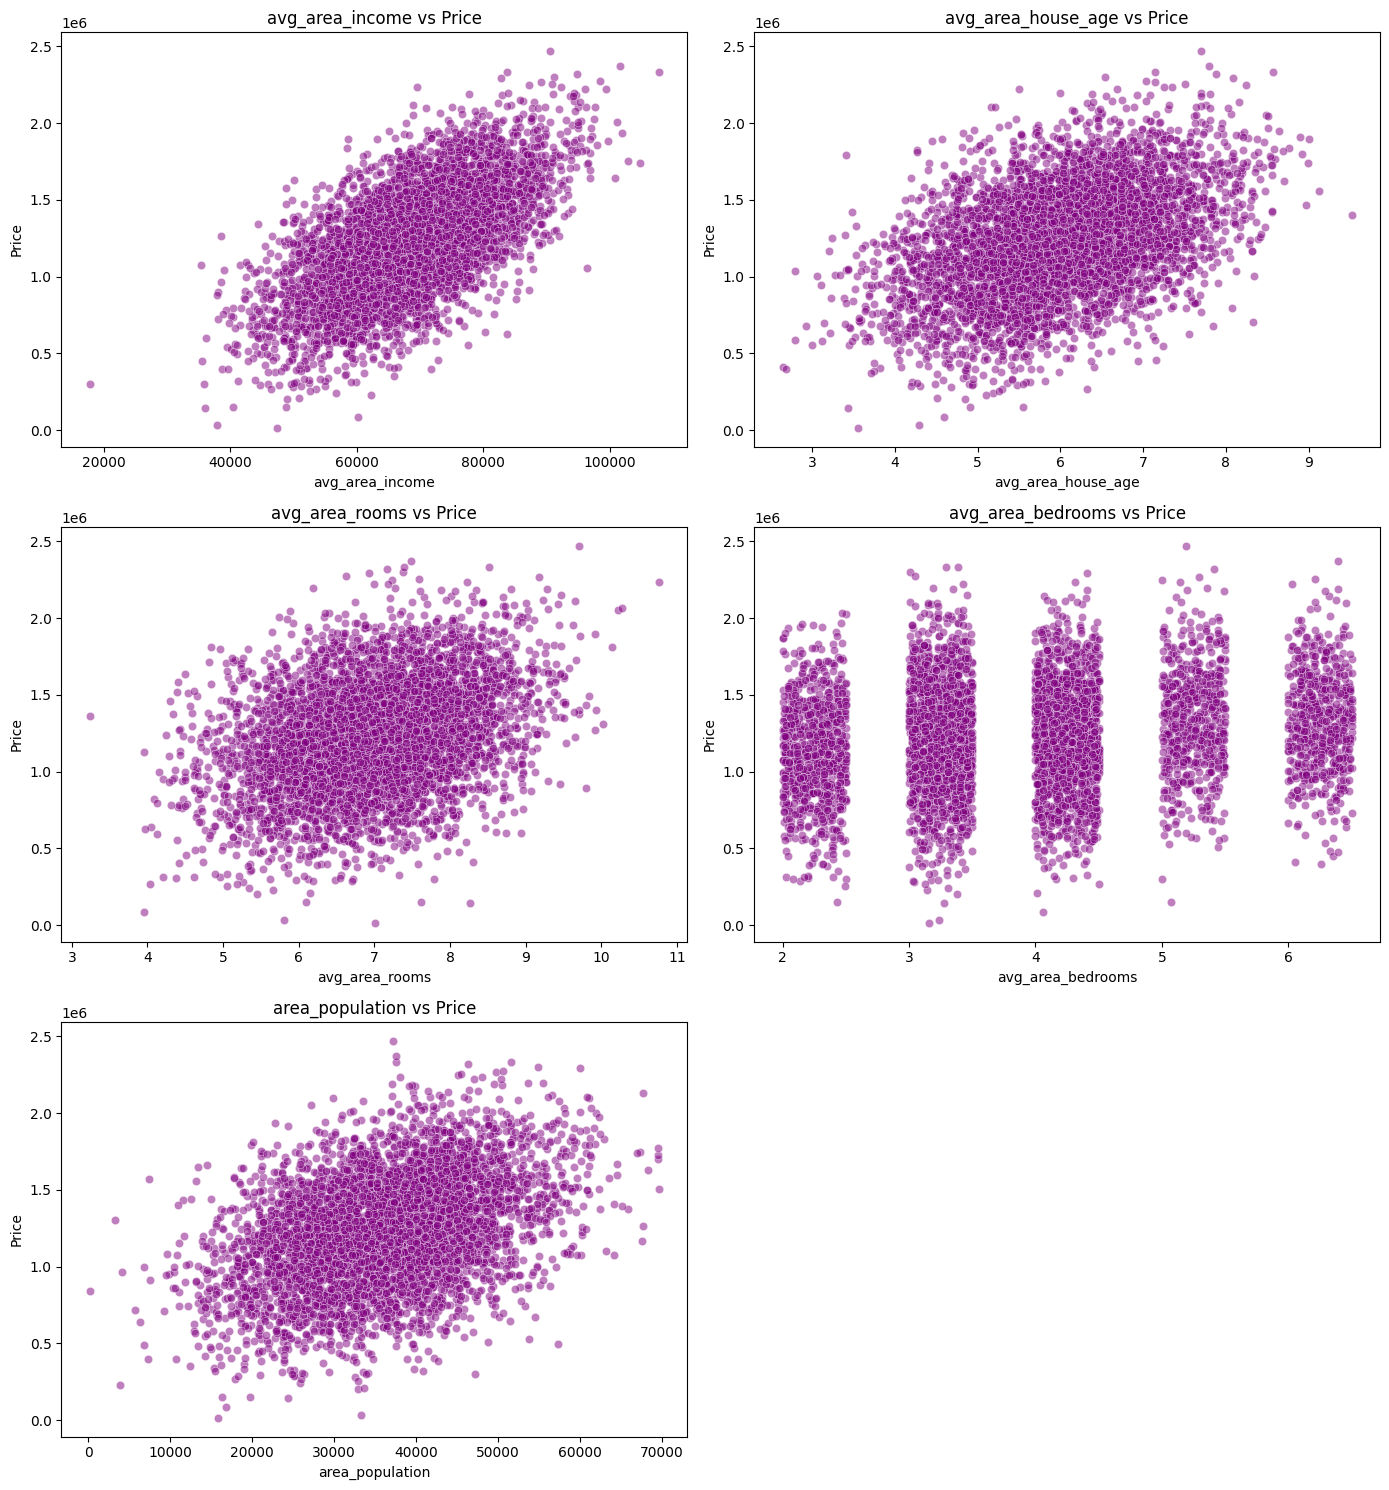

In [ ]:
# 3. Scatter-plot each feature against Price to visually confirm linear relationships
features_to_plot = [col for col in df.columns if col not in ['price', 'population_category']]

fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(14, 15))
axes = axes.flatten()

for i, col in enumerate(features_to_plot):
    if i < len(axes):
        sns.scatterplot(data=df, x=col, y='price', alpha=0.5, ax=axes[i], color='purple')
        axes[i].set_title(f'{col} vs Price')
        axes[i].set_xlabel(col)
        axes[i].set_ylabel('Price')


for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

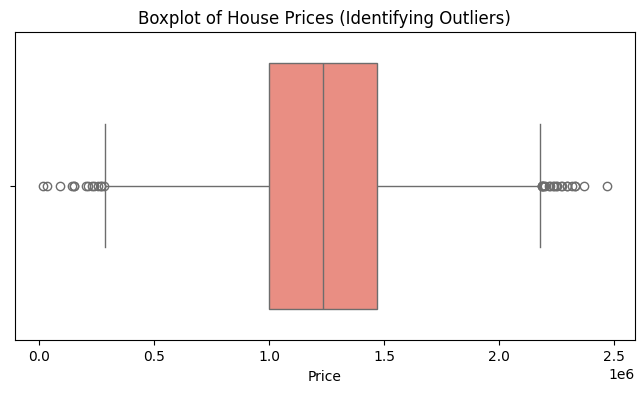

In [ ]:

plt.figure(figsize=(8, 4))
sns.boxplot(x=df['price'], color='salmon')
plt.title('Boxplot of House Prices (Identifying Outliers)')
plt.xlabel('Price')
plt.show()

In [ ]:
df['rooms_per_bedroom'] = df['avg_area_rooms'] / df['avg_area_bedrooms']
df['population_category'] = pd.qcut(df['area_population'], q=3, labels=['Low', 'Medium', 'High'])

R2 Score: 0.9180
MAE: $80881.07
RMSE: $100448.49


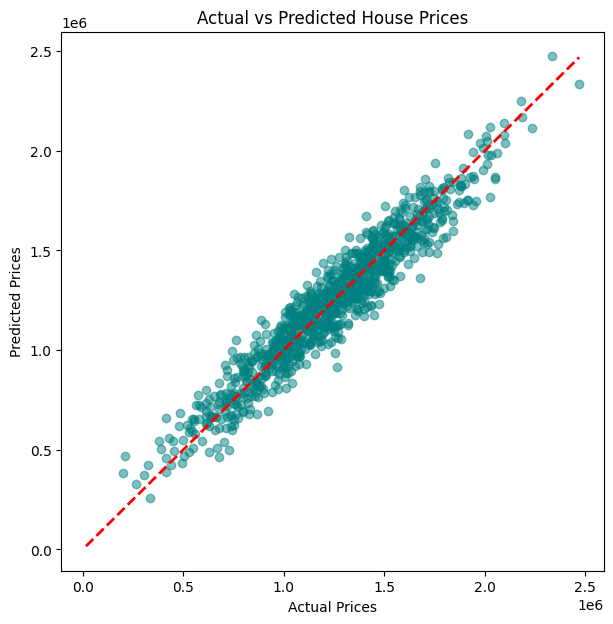

In [ ]:
import os
X = df.drop(columns=['price', 'population_category'])
y = df['price']

# Split data into train and test sets (80/20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train Linear Regression Model
model = LinearRegression()
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"R2 Score: {r2:.4f}")
print(f"MAE: ${mae:.2f}")
print(f"RMSE: ${rmse:.2f}")


plt.figure(figsize=(7, 7))
plt.scatter(y_test, y_pred, alpha=0.5, color='teal')
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2)
plt.xlabel('Actual Prices')
plt.ylabel('Predicted Prices')
plt.title('Actual vs Predicted House Prices')


os.makedirs('../Images', exist_ok=True)
plt.savefig('../Images/actual_vs_predicted.png')
plt.show()

In [ ]:
test_results = X_test.copy()
test_results['actual_price'] = y_test
test_results['predicted_price'] = y_pred
test_results['absolute_error'] = np.abs(test_results['actual_price'] - test_results['predicted_price'])
test_results['population_category'] = df.loc[X_test.index, 'population_category']

category_comparison = test_results.groupby('population_category').agg(
    sample_count=('absolute_error', 'count'),
    mean_absolute_error=('absolute_error', 'mean'),
    root_mean_squared_error=('absolute_error', lambda x: np.sqrt(np.mean(x**2)))
).reset_index()

print("\nModel Performance Across Population Density Categories:")
print(category_comparison)


Model Performance Across Population Density Categories:
  population_category  sample_count  mean_absolute_error  \
0                 Low           323         80626.647503   
1              Medium           338         80982.433760   
2                High           339         81022.410862   

   root_mean_squared_error  
0             98465.806053  
1            101705.758901  
2            101055.704817  


/tmp/ipykernel_588/2071932664.py:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  category_comparison = test_results.groupby('population_category').agg(
